# 1. Libraries

imported all the necessary libraries :

Pandas--> to upload the csv file


numpy--> for numerical calculations


matplotlib--> for plotting the graphs

sklearn--> for model training,metrics evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 2. Load and explore the dataset

I load the  housing dataset and checked its first rows, shape, column names, and data types. These made me to understand what the dataset is conveying , what and all the columns are most important

In [2]:
df = pd.read_csv("housing_data.csv")

print("Dataset shape (rows, cols):", df.shape)
display(df.head())
print("Column names:")
print(df.columns.tolist())

Dataset shape (rows, cols): (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


Column names:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual', 'Garage Cond', 'Paved Drive

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order,2930.0,NaN,NaN,NaN,1465.5,845.96247,1.0,733.25,1465.5,2197.75,2930.0
PID,2930.0,NaN,NaN,NaN,714464496.988737,188730844.64939,526301100.0,528477022.5,535453620.0,907181097.5,1007100110.0
MS SubClass,2930.0,NaN,NaN,NaN,57.387372,42.638025,20.0,20.0,50.0,70.0,190.0
MS Zoning,2930,7,RL,2273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Lot Frontage,2440.0,NaN,NaN,NaN,69.22459,23.365335,21.0,58.0,68.0,80.0,313.0
...,...,...,...,...,...,...,...,...,...,...,...
Mo Sold,2930.0,NaN,NaN,NaN,6.216041,2.714492,1.0,4.0,6.0,8.0,12.0
Yr Sold,2930.0,NaN,NaN,NaN,2007.790444,1.316613,2006.0,2007.0,2008.0,2009.0,2010.0
Sale Type,2930,10,WD,2536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sale Condition,2930,6,Normal,2413,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Check missing values and duplicate rows

I checked missing values and duplicate rows to find possible data-quality issues. The target column "SALE PRICE" is checked separately because rows without a known sale price cannot be used to train or evaluate this model.

In [5]:
print("Missing values by column:")
display(df.isnull().sum().sort_values(ascending=False).head(20).to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())
print("Missing SalePrice values:", df["SalePrice"].isnull().sum())

Missing values by column:


,Missing values
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Qual,159
Garage Yr Blt,159
Garage Cond,159


Duplicate rows: 0
Missing SalePrice values: 0


## 4. Selecting features and target

x contains the input columns used to predict the price, and y contains the actual saleprice. I use a few meaningful numerical features from the dataset so the model can learn from house size, quality, age, basement space, and garage space.

In [6]:
df = df.dropna(subset=["SalePrice"]).copy()

features = [
    "Gr Liv Area",
    "Overall Qual",
    "Total Bsmt SF",
    "Garage Area",
    "Full Bath",
    "Year Built"
]

X = df[features].copy()
y = df["SalePrice"].copy()

print("Selected features:", features)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Selected features: ['Gr Liv Area', 'Overall Qual', 'Total Bsmt SF', 'Garage Area', 'Full Bath', 'Year Built']
Feature shape: (2930, 6)
Target shape: (2930,)


## 5. Split into training and testing data

I used 80% of the data for training and 20% for testing,The test set is kept aside until the final evaluation, and random_state=0 makes the split reproducible

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (2344, 6)
X_test : (586, 6)
y_train: (2344,)
y_test : (586,)


## 6. Handle missing feature values

I check missing values in the selected features, then fill them using each feature's median calculated from the training set. The same medians are used for the test set so the test data does not influence the cleaning process.

In [8]:
print("Missing values in training features:")
display(X_train.isnull().sum())
print("Missing values in testing features:")
display(X_test.isnull().sum())

feature_medians = X_train.median()

X_train = X_train.copy()
X_test = X_test.copy()

X_train = X_train.fillna(feature_medians)
X_test = X_test.fillna(feature_medians)

print("Remaining missing values in training:", X_train.isnull().sum().sum())
print("Remaining missing values in testing:", X_test.isnull().sum().sum())

Missing values in training features:


Gr Liv Area      0
Overall Qual     0
Total Bsmt SF    1
Garage Area      1
Full Bath        0
Year Built       0
dtype: int64

Missing values in testing features:


Gr Liv Area      0
Overall Qual     0
Total Bsmt SF    0
Garage Area      0
Full Bath        0
Year Built       0
dtype: int64

Remaining missing values in training: 0
Remaining missing values in testing: 0


## 7. Inspect and handle outliers

I inspect the selected numerical features with a box plot and use the IQR rule to identify possible outliers. The lower and upper limits are calculated from training data only, then the same limits are applied to both sets; the target prices are not changed.

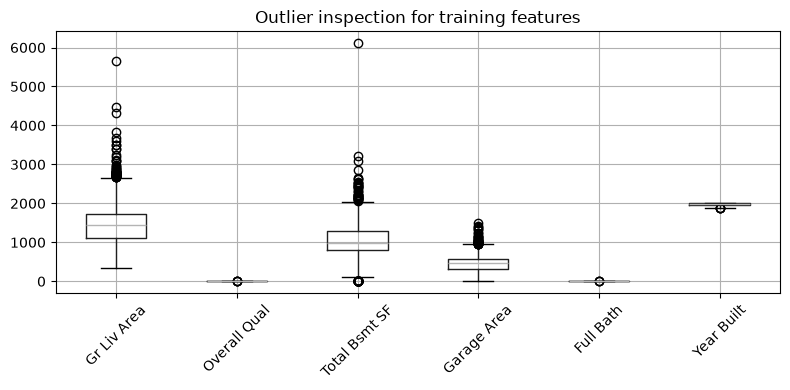

Lower IQR bounds:


,Lower bound
Gr Liv Area,188.125
Overall Qual,2.000
Total Bsmt SF,38.625
Garage Area,-57.125
Full Bath,-0.500
Year Built,1885.000


Upper IQR bounds:


,Upper bound
Gr Liv Area,2665.125
Overall Qual,10.000
Total Bsmt SF,2055.625
Garage Area,955.875
Full Bath,3.500
Year Built,2069.000


In [9]:
plt.figure(figsize=(8, 4))
X_train.boxplot()
plt.title("Outlier inspection for training features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Lower IQR bounds:")
display(lower_bound.to_frame("Lower bound"))
print("Upper IQR bounds:")
display(upper_bound.to_frame("Upper bound"))

In [10]:
X_train = X_train.clip(lower=lower_bound, upper=upper_bound, axis=1)
X_test = X_test.clip(lower=lower_bound, upper=upper_bound, axis=1)

print("Outlier capping applied using training-set IQR bounds.")

Outlier capping applied using training-set IQR bounds.


## 8. Build the Linear Regression model

The model learns a relationship between the selected house features and the selling price. Because there are several input columns, the prediction is calculated using an intercept and a coefficient for each feature.

In [11]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Multiple Linear Regression model trained.")

Multiple Linear Regression model trained.


In [12]:
print("Intercept:", lr_model.intercept_)

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": lr_model.coef_
})
display(coefficients)

Intercept: -740567.1235330047


,Feature,Coefficient
0,Gr Liv Area,61.584709
1,Overall Qual,20792.527272
2,Total Bsmt SF,40.620097
3,Garage Area,48.166813
4,Full Bath,-9322.482944
5,Year Built,331.051741


## 9. Compare actual and predicted training prices

With multiple features, a single straight line cannot show the whole model in a two-dimensional graph. Instead, this plot compares the actual training prices with the model's predicted prices; points closer to the diagonal indicate better predictions.

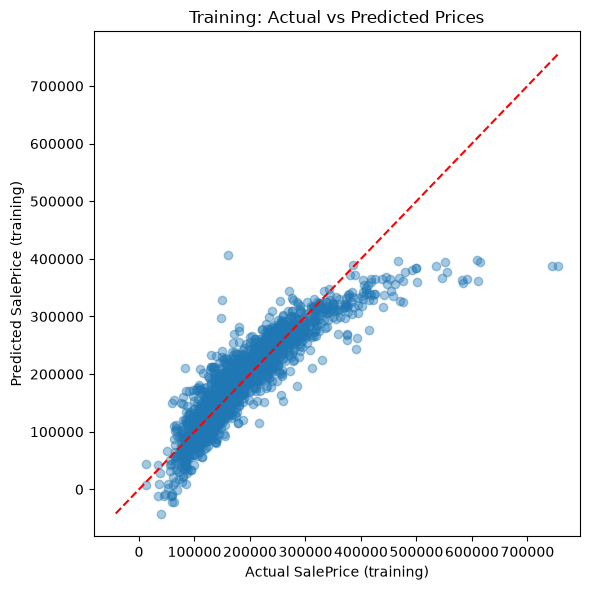

In [13]:
y_pred_train = lr_model.predict(X_train)

plt.figure(figsize=(6, 6))
plt.scatter(y_train, y_pred_train, alpha=0.4)
plot_min = min(y_train.min(), y_pred_train.min())
plot_max = max(y_train.max(), y_pred_train.max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], "r--")
plt.xlabel("Actual SalePrice (training)")
plt.ylabel("Predicted SalePrice (training)")
plt.title("Training: Actual vs Predicted Prices")
plt.tight_layout()
plt.show()

### 10. Make predictions

I use the trained model to predict prices for both training and test houses. The test predictions are kept for the final evaluation of houses the model did not train on.

In [14]:
y_pred_train = lr_model.predict(X_train)
y_pred_test = lr_model.predict(X_test)

print("Training predictions:", y_pred_train.shape)
print("Testing predictions:", y_pred_test.shape)

Training predictions: (2344,)
Testing predictions: (586,)


## 11. Evaluate training and test performance

MAE is the average absolute prediction error, MSE is the average squared error, RMSE is the square root of MSE, and R² measures how much price variation the model explains. I report these metrics for both datasets to compare fit on seen data with performance on unseen data.

In [15]:
def show_metrics(actual, predicted, data_name):
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    print(data_name)
    print("MAE :", round(mae, 2))
    print("MSE :", round(mse, 2))
    print("RMSE:", round(rmse, 2))
    print("R-squared:", round(r2, 4))
    print()

show_metrics(y_train, y_pred_train, "Training results")
show_metrics(y_test, y_pred_test, "Testing results")

Training results
MAE : 24071.27
MSE : 1274651531.15
RMSE: 35702.26
R-squared: 0.7987

Testing results
MAE : 24743.26
MSE : 1343240069.11
RMSE: 36650.24
R-squared: 0.7954



## 12. Check actual versus predicted test prices

This plot compares actual test prices with predicted test prices. Points close to the diagonal line are more accurate; points farther away show larger prediction errors.

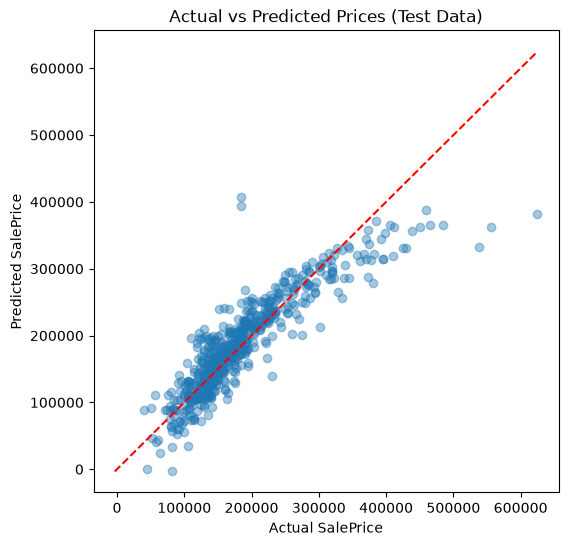

In [16]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_test, alpha=0.4)

plot_min = min(y_test.min(), y_pred_test.min())
plot_max = max(y_test.max(), y_pred_test.max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], "r--")

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted Prices (Test Data)")
plt.show()

## 13. Conclusion

This project predicts house sale prices using multiple numerical features: `Gr Liv Area`, `Overall Qual`, `Total Bsmt SF`, `Garage Area`, `Full Bath`, and `Year Built`. These describe living space, overall quality, basement area, garage area, bathroom count, and the construction year.

I explored the dataset, checked missing values and duplicate rows, split the data into training and testing sets, filled missing feature values using training medians, and inspected and capped possible outliers using training-set IQR limits. I trained a Linear Regression model and evaluated it on both training and test data using MAE, MSE, RMSE, and R².

Use the metrics printed above to explain how well the model predicts unseen house prices. A lower test MAE/RMSE and a higher test R² generally indicate better performance. The model is still a simple baseline and does not use categorical features such as neighborhood or house style.

## 14. Save the trained model for web deployment

I save the trained Linear Regression model, the IQR clipping bounds, the feature medians, and the test evaluation metrics to a file (`house_model.pkl`) using `joblib`. This allows the Streamlit web application (`app.py`) to load the trained model directly without retraining.

In [17]:
import joblib

saved_package = {
    "model": lr_model,
    "features": features,
    "lower_bound": lower_bound,
    "upper_bound": upper_bound,
    "medians": feature_medians,
    "metrics": {
        "test_mae": 24743.26,
        "test_rmse": 36650.24,
        "test_mse": 1343240069.11,
        "test_r2": 0.7954
    }
}

joblib.dump(saved_package, "house_model.pkl")
print("Model saved to house_model.pkl successfully!")

Model saved to house_model.pkl successfully!
